Lo stato iniziale del sistema composto da due qubit è:


<IPython.core.display.Latex object>

A seguito dell'operazione Controlled-Not lo stato del sistema è:


<IPython.core.display.Latex object>

Infine, a seguito dell'operazione di Hadamard lo stato del sistema è:


<IPython.core.display.Latex object>

Come risulta evidente dalla formula del vettore di stato del sistema, il qubit di controllo (qubit 0) si trova nello stato classico 1 


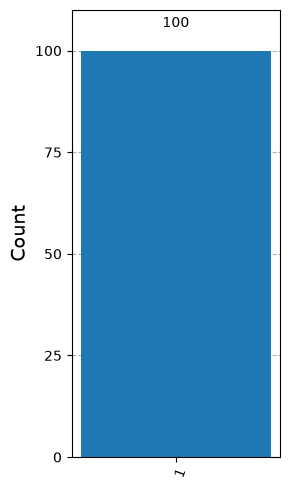

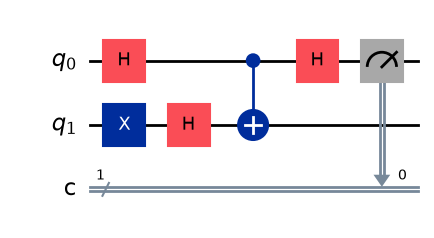

In [31]:
"""
Questo script dimostra il fenomeno quantistico del "Phase Kickback" (ritorno di fase) utilizzando la libreria Qiskit.

Il programma esegue i seguenti passaggi:
1. Inizializza un circuito con 2 qubit e 1 bit di misurazione classico.
2. Prepara il qubit di controllo (0) nello stato di sovrapposizione |+>.
3. Prepara il qubit bersaglio (1) nello stato di sovrapposizione |->.
4. Applica una porta Controlled-NOT (CX). In questa specifica configurazione, il qubit bersaglio non cambia, ma la sua fase negativa viene "trasferita" al qubit di controllo, che passa dallo stato |+> allo stato |-> (Phase Kickback).
5. Applica una porta Hadamard al qubit di controllo. Poiché la sua fase è stata invertita, il qubit tornerà nello stato classico |1> anziché |0>.
6. Misura il qubit di controllo ed esegue una simulazione (100 shots) per confermare il risultato tramite un istogramma.

Durante l'esecuzione, lo script stampa in formato LaTeX i vettori di stato del sistema nei vari passaggi per mostrare matematicamente l'evoluzione dei qubit, e genera infine il disegno del circuito.
"""


import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector, 
    plot_state_qsphere,
    circuit_drawer, 
    plot_histogram
)

#Creazione Circuito
qc = QuantumCircuit(2,1)

# Preparazione dello stato del qubit di controllo, lo porto nello stato equiprobabilistico |+>
qc.h(0) 

# Preparazione dello stato del qubit bersaglio
#Trasformo il qubit nello stato classico 1 e lo porto nello stato equiprobabilististico |->
qc.x(1) 
qc.h(1) 

# Rappresento con latex lo stato inziale del sistema composto dai due qubit
print("Lo stato iniziale del sistema composto da due qubit è:")
s0 = Statevector(qc)
display(s0.draw("latex"))

# Operazione Controlled-Not su i due qubit
qc.cx(0,1)

# Rappresento con latex lo stato inziale del sistema composto dai due qubit, a seguito dell'esecuzione dell'operazione Cnot
print("A seguito dell'operazione Controlled-Not lo stato del sistema è:")
s1 = Statevector(qc)
display(s1.draw("latex"))

# Applico una porta di Hadamard al qubit 0, per ripotarlo allo stato classico
qc.h(0)

# Rappresento con latex lo stato probabilistico dei due qubit s2. 
# Dopo l'hadamard-gate sul qubit di controllo, questo si trova nello stato opposto a quello inziale ovvero |1> (come dimostra la simulazione succesiva)
print("Infine, a seguito dell'operazione di Hadamard lo stato del sistema è:")
s2 = Statevector(qc)
display(s2.draw("latex"))
print("Come risulta evidente dalla formula del vettore di stato del sistema, il qubit di controllo (qubit 0) si trova nello stato classico 1 ")

# Misuro lo stato del qubit di controllo
qc.measure(0,0)

# Eseguo una simulazione del circuito, con 100 shots
simulator = AerSimulator()
job = simulator.run(qc, shots = 100)
result= job.result()
counts = result.get_counts()
display(plot_histogram(counts, figsize=(3, 5)))

# Rappresento graficamente il circuito
qc.draw("mpl")





